# The Sidekick
The Sidekick is a personal co-worker you can give a task and a definition of success, and it will work away using a real browser, a filesystem, web search and more, until it has met your criteria or needs to ask you something.

The Sidekick's worker is a single create_agent from Layer 3, but we wrap it in our own loop rather than letting a framework run the show, and we reach down to Layer 1 tools and out to MCP servers as we please. You pick the altitude that suits each part of the job.

## How it is built
**The worker** is one `create_agent` carrying every tool, with a memory, and a stack of middleware.
- **A visible plan**: `TodoListMiddleware` gives it a todo list, and we surface that plan in the UI.
- **Guardrails, each one line of middleware**:
    - PII Reduction: `PIIMiddleware` redacts email addresses from the input, and scrubs credit card numbers even out of what the browser sees.
    - A hard budger cap: `ModelCallLimitMiddleware` caps a run at 30 model calls, so a lost agent cannot burn money forever.
- Our own `TolerateToolErrors` middleware hands tool failures back to the model so it can recover.
- **Human-in-the-loop**: It pauses for approval, and can hand you the browser.
    - `HumanInTheLoopMiddleware` pauses for your approval before a push notification goes out, and powers the `request_human_help` tool, which lets the agent hand the browser back to you for logins, captcha and two-factor prompts.

**The Evaluator**, our own loop judges each reply against your success criteria. Around the worker we run a small loop of our own:
1. The worker attempts the task.
2. An evaluator, which is just a model with structured output, checks the answer against your success criteria, with the worker's tool calls as evidence.
3. If the criteria are met, or the worker has a question, we stop and show you the result. Otherwise we hand the feedback back to the worker and let it try again.

One more thing happens under the hood: the browser and filesystem MCP servers run in persistent sessions held open for the Sidekick's lifetime, so the browser keeps its state between tool calls and can even be handed to a human mid-task. The sessions live in a small background task in `sidekick_tools.py`, because the stdio transport must be opened and closed from the same task. A welcome side effect is that `cleanup()` really does close the browser.

We will build up to it in three steps. First the simplest possible version with no evaluator, then human-in-the-loop with middleware, then the full Sidekick from the project modules.

## One adjustment for Windows
Same as Day 3: when a stdio MCP server is launched from inside Jupyter on Windows, the kernel's stderr has no real file descriptor and the launch fails. The cell below redirects the servers' error log so everything works. On Mac and Linux it does nothing.

In [ ]:
import sys

if sys.platform == "win32":
    import subprocess
    from functools import partial
    import langchain_mcp_adapters.sessions as mcp_sessions

    mcp_sessions.stdio_client = partial(mcp_sessions.stdio_client, errlog=subprocess.DEVNULL)
    print("Applied the Windows adjustment")
else:
    print("Not Windows, so nothing to do here")

In [1]:
import os
from dotenv import load_dotenv
from langchain.agents import create_agent
from langchain.agents.middleware import HumanInTheLoopMiddleware
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import Command

from sidekick_tools import search, send_push_notification, wikipedia_lookup
from sidekick import Sidekick

load_dotenv(override=True)

# -------------------- Clean all base urls --------------------
os.environ.pop("GROQ_BASE_URL", None)
os.environ.pop("GEMINI_BASE_URL", None)
os.environ.pop("OPENROUTER_BASE_URL", None)
os.environ.pop("GLM_Z_BASE_URL", None)
os.environ.pop("OLLAMA_BASE_URL", None)
os.environ.pop("OLLAMA_API_BASE", None)

'http://localhost:11434/v1'

## Step 1: the simplest Sidekick, with no evaluator
At its plainest, the Sidekick is a create_agent with a few tools and a memory, plus a tiny function that runs one turn of conversation. The tools are old friends: the same off-the-shelf Serper search, Wikipedia tools, and a push notification tool. There is no evaluator here, so the worker simply does its best and replies. For many tasks this simple version is all you need, and everything that follows adds layers on top of it.

In [14]:
from langchain.chat_models import init_chat_model

model = init_chat_model("groq:openai/gpt-oss-120b",
                        temperature=0.2,
                        seed=42,
                        configurable_fields="any",
                        config_prefix="foo",
                        )

'''
model = init_chat_model(
    model="MODEL_NAME",
    model_provider="openai",
    configurable_fields=This allows us to configure other params like temperature, max_tokens, etc at runtime.
    base_url="BASE_URL",
    api_key="YOUR_API_KEY",
)

model.invoke("what's your name")
# GPT-5.5 response with temperature 0 (as set in default)

# Invoke overriding model and temperature at runtime via config.
# Note the use of the "foo_" prefix on the config keys, which matches
# the config_prefix we set when initializing the model.
model.invoke(
    "what's your name",
    config={
        "configurable": {
            "foo_model": "anthropic:claude-opus-4-7",
            "foo_temperature": 0.6,
        }
    },
)'''
model.profile

/Users/marcelogomesmarques/Projects/LLM/master_rag/src/master_rag/2-Document-Engineering-And-Smart-Indexing/3.4-PdfSplitter/Marker/marker-env/lib/python3.13/site-packages/pydantic/main.py:280: UserWarning: WARNING! seed is not default parameter.
                    seed was transferred to model_kwargs.
                    Please confirm that seed is what you intended.
  validated_self = self.__pydantic_validator__.validate_python(data, self_instance=self)


{'name': 'GPT OSS 120B',
 'release_date': '2025-08-05',
 'last_updated': '2026-05-27',
 'open_weights': True,
 'max_input_tokens': 131072,
 'max_output_tokens': 65536,
 'text_inputs': True,
 'image_inputs': False,
 'audio_inputs': False,
 'video_inputs': False,
 'text_outputs': True,
 'image_outputs': False,
 'audio_outputs': False,
 'video_outputs': False,
 'reasoning_output': True,
 'tool_calling': True,
 'structured_output': True,
 'attachment': False,
 'temperature': True}

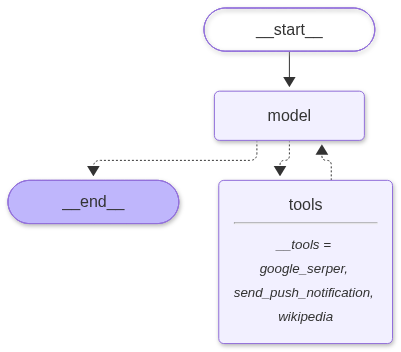

In [15]:
simple_worker = create_agent(
    model="groq:openai/gpt-oss-120b",
    tools=[search, send_push_notification, wikipedia_lookup],
    system_prompt="You are Sidekick, a helpful personal assistant. Use your tools to complete the task.",
    checkpointer=InMemorySaver(),
)

simple_worker

In [16]:
async def ask(worker, message):
    config = {"configurable": {"thread_id": "simple-sidekick"}}
    result = await worker.ainvoke({"messages": [{"role": "user", "content": message}]}, config=config)
    return result["messages"][-1].content

reply = await ask(simple_worker, "Search for who won the Nobel Prize in Physics in 2023 and send a push notification with a short summary.")
print(reply)

The 2023 Nobel Prize in Physics was awarded to **Pierre Agostini**, **Ferenc Krausz**, and **Anne L’Huillier** for their pioneering experimental methods that generate attosecond laser pulses, enabling scientists to observe electron dynamics in atoms and molecules.


## Step 2: human-in-the-loop with middleware

LangChain supports allowing the agent to pause to collect feedback from a user. We tell `HumanInTheLoopMiddleware` which tools to pause on, and the agent stops and waits for our decision instead of running them.

When the agent reaches such a tool, the run pauses and returns an interrupt that describes the pending action. We can then approve, edit, reject, or respond, and resume.

In [17]:
from langchain_core.tools import tool

@tool
def book_meeting(person: str, day: str) -> str:
    """Book a meeting with a person on a given day."""
    return f"Meeting booked with {person} on {day}."

approval_agent = create_agent(
    model="groq:openai/gpt-oss-120b",
    tools=[book_meeting],
    system_prompt="You are a scheduling assistant. Use the book_meeting tool.",
    middleware=[HumanInTheLoopMiddleware(interrupt_on={"book_meeting": True})],
    checkpointer=InMemorySaver(),
)

config = {"configurable": {"thread_id": "approval-demo"}}
result = await approval_agent.ainvoke(
    {"messages": [{"role": "user", "content": "Book a meeting with Sam on Friday."}]}, config
)

interrupt = result["__interrupt__"][0]
print("The agent paused and is asking for approval:")
print(interrupt.value["action_requests"][0]["description"])

The agent paused and is asking for approval:
Tool execution requires approval

Tool: book_meeting
Args: {'day': 'Friday', 'person': 'Sam'}


The agent is waiting. We approve the action, and the run continues from exactly where it paused.

Hold this thought: the full Sidekick uses this same middleware to gate its push notifications, and to power a `request_human_help` tool that lets the agent ask YOU to do something in its browser window, like logging in to a site, and carry on once you have done it.

In [18]:
resumed = await approval_agent.ainvoke(Command(resume={"decisions": [{"type": "approve"}]}), config)
print(resumed["messages"][-1].content)

Your meeting with Sam has been scheduled for Friday. Let me know if there’s anything else I can help with!


## Choosing how to respond
We approved that booking, but approve is only one of the choices. Your resume carries one decision per paused tool call, and each decision can be one of three kinds:

- **Approve** runs the tool exactly as proposed: `{"type": "approve"}`.
- **Edit** runs it, but with arguments you change first: `{"type": "edit", "edited_action": {"name": "book_meeting", "args": {"person": "Sam", "day": "Monday"}}}`.
- **Reject** skips the tool and hands a note back to the model so it can try another way: `{"type": "reject", "message": "No meetings on Fridays"}`.

So to decline the booking rather than approve it, you would resume like this instead:

```python
await approval_agent.ainvoke(
    Command(resume={"decisions": [{"type": "reject", "message": "No meetings on Fridays"}]}), config
)
```

You decide which of these a tool allows when you configure the middleware: `interrupt_on={"book_meeting": True}` permits all three, while `{"book_meeting": {"allowed_decisions": ["approve", "reject"]}}` would offer approve or reject but no editing. The Sidekick keeps things to plain approval, but edit and reject are the same one line of resume away.

In [19]:
config = {"configurable": {"thread_id": "rejection-demo2"}}
result = await approval_agent.ainvoke(
    {"messages": [{"role": "user", "content": "Book a meeting with Sam on Friday."}]}, config
)

interrupt = result["__interrupt__"][0]
print("The agent paused and is asking for approval:")
print(interrupt.value["action_requests"][0]["description"])

The agent paused and is asking for approval:
Tool execution requires approval

Tool: book_meeting
Args: {'day': 'Friday', 'person': 'Sam'}


In [20]:
resumed = await approval_agent.ainvoke(Command(resume={"decisions": [{"type": "reject", "message": "Rejected - no meetings on Fridays"}]}), config)
print(resumed["messages"][-1].content)

I’m sorry, but I can’t schedule meetings for Fridays. Could you let me know another day that works for you and Sam?


## Step 3: the full Sidekick
The complete version lives in `sidekick.py` and `sidekick_tools.py`. The worker has the full toolkit: a headed browser and a sandbox filesystem through persistent MCP sessions, plus web search, Wikipedia, push notifications and `request_human_help`. The middleware stack from the start of this lab is all in place, and the evaluator loop checks each answer against your success criteria, using the worker's tool calls as evidence, sending the worker back to try again when needed.

This is the whole stack in one object. The worker is a Layer 3 create_agent, its tools are Layer 1 `@tool` functions alongside MCP servers, its memory is a Layer 2 checkpointer, and the loop around it is code you wrote yourself. You chose the altitude for each part.

Let us bring one to life and start with a quick browser errand. Watch the window open and drive itself. The top story on Hacker News changes through the day, so you will see a different headline than the one shown here.

In [2]:
sidekick = Sidekick()
await sidekick.setup()
print(f"Sidekick ready with {len(sidekick.tools)} tools")

[11/12/26 15:38:10] INFO     Proxy detected connected client - reusing existing session for all       ]8;id=13468019;file:///Users/marcelogomesmarques/Projects/LLM/master_rag/.venv/lib/python3.13/site-packages/fastmcp/server/providers/proxy.py\proxy.py]8;;\:]8;id=13468020;file:///Users/marcelogomesmarques/Projects/LLM/master_rag/.venv/lib/python3.13/site-packages/fastmcp/server/providers/proxy.py#1388\1388]8;;\
                             requests. This may cause context mixing in concurrent scenarios, and the              
                             session's existing settings apply, so backend results are validated                   
                             against their declared output schema rather than relayed as-is. Pass a                
                             disconnected client to avoid both.                                                    

[11/12/26 15:38:11] INFO     Proxy detected connected client - reusing existing session for all       ]8;id=13468025;file:///Users/marcelogomesmarques/Projects/LLM/master_rag/.venv/lib/python3.13/site-packages/fastmcp/server/providers/proxy.py\proxy.py]8;;\:]8;id=13468026;file:///Users/marcelogomesmarques/Projects/LLM/master_rag/.venv/lib/python3.13/site-packages/fastmcp/server/providers/proxy.py#1388\1388]8;;\
                             requests. This may cause context mixing in concurrent scenarios, and the              
                             session's existing settings apply, so backend results are validated                   
                             against their declared output schema rather than relayed as-is. Pass a                
                             disconnected client to avoid both.                                                    

ollama:qwen3.5:4b
Sidekick ready with 25 tools


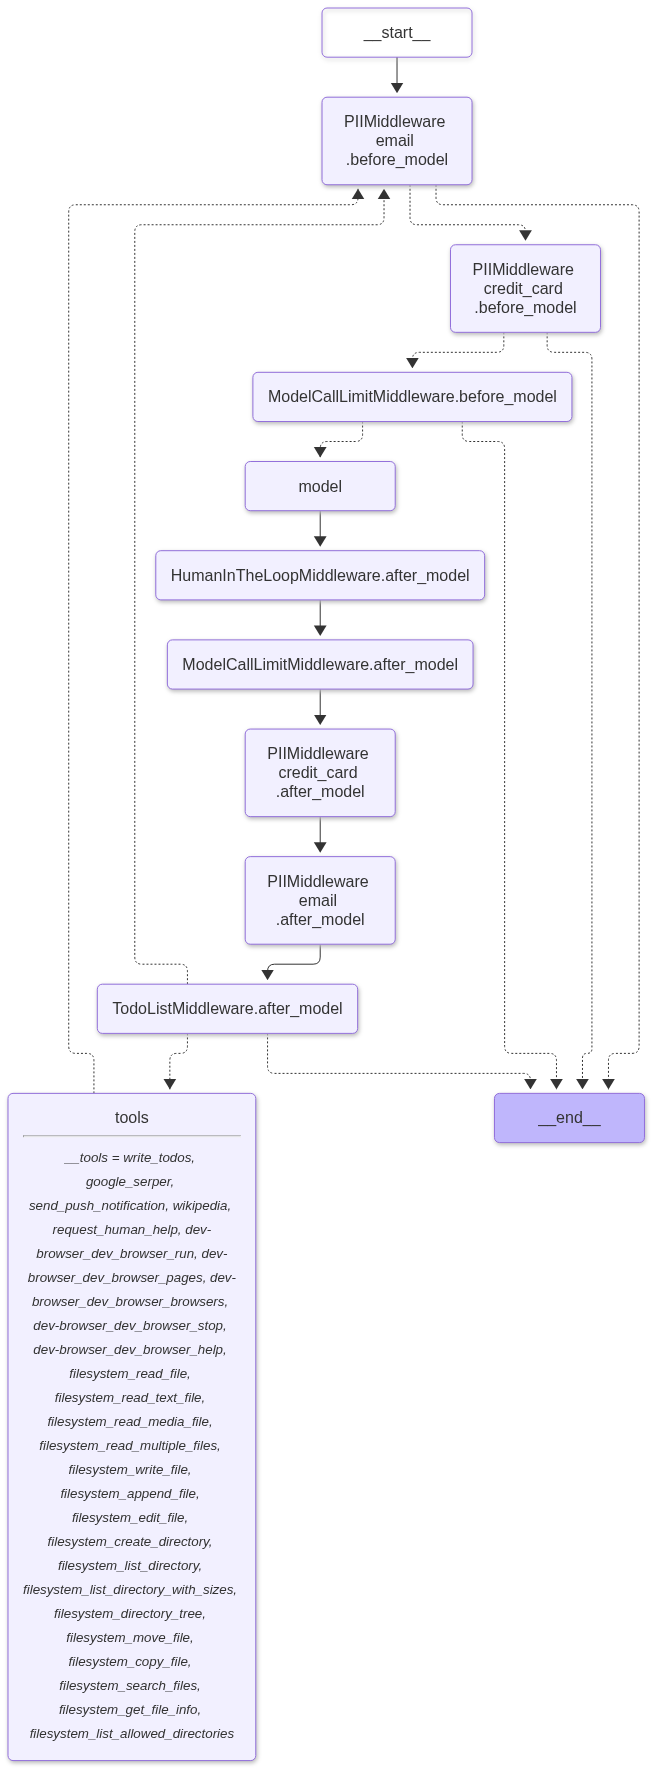

In [6]:
from langchain_core.runnables.graph_mermaid import draw_mermaid_png
from IPython.display import Image

mm = sidekick.worker.get_graph().draw_mermaid().replace("[", " ").replace("]", " ")
Image(draw_mermaid_png(mm, output_file_path="graph.png"))

In [3]:
history = await sidekick.run_turn(
    message="Go to Hacker News at https://news.ycombinator.com/ and tell me the only the title of the current top story.",
    success_criteria="The reply names a specific story currently on the Hacker News front page.",
    history=[],
)
for entry in history:
    print(f"[{entry['role']}] {entry['content'][:200]}\n")

[user] Go to Hacker News at https://news.ycombinator.com/ and tell me the only the title of the current top story.

[assistant] The current top story on Hacker News is:

**Jensen Huang resigns**

[assistant] Evaluator: The assistant successfully identified and reported a specific story title from the Hacker News front page, meeting the success criteria. No further input is needed.



## The finale: a real errand
Now a task worthy of the week: find me the best flight. This needs a plan, a stretch of real browsing, a file, and a push notification, and it ends with the Sidekick asking your permission. One detail to notice in `sidekick.py`: the worker's system prompt carries a practical trick, that Google Flights accepts a natural language query straight in the URL, giving your agent specialist abilities.

While it works, watch the browser window, and peek at the plan: the worker maintains a todo list through its `write_todos` tool, and the Sidekick exposes it as `sidekick.todos`.

In [4]:
flight_task = """Find me the best round-trip flight from New York to London, leaving about a month from now
and returning a week later. I care about price first, then total journey time, and I would rather avoid
itineraries with two or more stops. Write your recommendation with the top three options to flights.md,
then send me a push notification with the price of your top pick."""

flight_criteria = "flights.md is written with three specific options including airline, times and price, plus a clear recommendation, and a push notification was sent with the recommended price."

history = await sidekick.run_turn(flight_task, flight_criteria, [])
print(history[-1]["content"])

Waiting for your approval:
Tool execution requires approval

Tool: send_push_notification
Args: {'text': 'Flight recommendation (Dec 12–19, 2026): Top pick is American/British Airways (1 stop each way) for $744 USD round-trip. Full details saved to flights.md.'}


The Sidekick has done the work, and now it is paused, asking permission to send the notification. Its plan tells the story:

In [5]:
for todo in sidekick.todos:
    print(f"[{todo['status']}] {todo['content']}")

[completed] Check browser connection and current open pages
[completed] Search Google Flights for round-trip flights from New York (NYC) to London (LON) leaving around December 12, 2026 and returning around December 19, 2026
[completed] Analyze flight options based on price (lowest first), total journey time (shortest next), and avoiding 2+ stops
[in_progress] Write the recommendation with top three specific options (airline, times, price) to flights.md
[pending] Send a push notification with the price of the top pick


We approve, the notification arrives on your phone, and the evaluator confirms the criteria were met, with the tool calls as its evidence.

In [7]:
if sidekick.paused:
    history = await sidekick.resume(history)
for entry in history[-2:]:
    print(f"[{entry['role']}] {entry['content']}\n")

[user] Find me the best round-trip flight from New York to London, leaving about a month from now
and returning a week later. I care about price first, then total journey time, and I would rather avoid
itineraries with two or more stops. Write your recommendation with the top three options to flights.md,
then send me a push notification with the price of your top pick.

[assistant] Waiting for your approval:
Tool execution requires approval

Tool: send_push_notification
Args: {'text': 'Flight recommendation (Dec 12–19, 2026): Top pick is American/British Airways (1 stop each way) for $744 USD round-trip. Full details saved to flights.md.'}



## The Gradio app
`app.py` wraps all of this in a chat interface: a request box, a success criteria box, the Sidekick's plan updating live beside the chat while it works, and an Approve button that appears whenever it pauses for your say-so. Reset really does close the browser now, since the persistent MCP sessions shut down cleanly.

The look and feel lives in `styles.py` as a theme, a CSS constant and a JS constant. A Gradio 6 note: these are passed to `launch()`, not to `gr.Blocks()` as in older Gradio. Run the app from a terminal with `uv run app.py`, or launch the very same interface right here:

## Suggestions to use on the UI
Request:
Find me the best round-trip flight from Porto Alegre to Miami, leaving about a month from now and returning a week later. I care about price first, the total journey time, and I would rather avoid itineraries with two or more stops. Write your top three recommendations to poa_flights.md, then send me a push notification with the recommended price and total duration for each trip.

Success Criteria:
poa_flights.md is written with three specific options, including airline, times, and price, plus a clear recommendation, and a push notification was sent with the recommended price and the total duration of each trip.

In [4]:
from app import ui, LAUNCH_STYLE

ui.launch(inbrowser=True, **LAUNCH_STYLE)

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


[11/12/26 15:40:48] INFO     Proxy detected connected client - reusing existing session for all       ]8;id=13468031;file:///Users/marcelogomesmarques/Projects/LLM/master_rag/.venv/lib/python3.13/site-packages/fastmcp/server/providers/proxy.py\proxy.py]8;;\:]8;id=13468032;file:///Users/marcelogomesmarques/Projects/LLM/master_rag/.venv/lib/python3.13/site-packages/fastmcp/server/providers/proxy.py#1388\1388]8;;\
                             requests. This may cause context mixing in concurrent scenarios, and the              
                             session's existing settings apply, so backend results are validated                   
                             against their declared output schema rather than relayed as-is. Pass a                
                             disconnected client to avoid both.                                                    

[11/12/26 15:40:49] INFO     Proxy detected connected client - reusing existing session for all       ]8;id=13468037;file:///Users/marcelogomesmarques/Projects/LLM/master_rag/.venv/lib/python3.13/site-packages/fastmcp/server/providers/proxy.py\proxy.py]8;;\:]8;id=13468038;file:///Users/marcelogomesmarques/Projects/LLM/master_rag/.venv/lib/python3.13/site-packages/fastmcp/server/providers/proxy.py#1388\1388]8;;\
                             requests. This may cause context mixing in concurrent scenarios, and the              
                             session's existing settings apply, so backend results are validated                   
                             against their declared output schema rather than relayed as-is. Pass a                
                             disconnected client to avoid both.                                                    

ollama:qwen3.5:4b


In [7]:
ui.close()

Closing server running on port: 7860
